# 02 — Machine Learning Modeling

### Objective
To develop and evaluate machine learning models for predicting customer churn and identify the best-performing model for detecting customers at risk of discontinuing the service.

### Modeling Approach
Three machine learning algorithms were compared, namely **Logistic Regression, Random Forest, and XGBoost**, using stratified cross-validation. Model performance was evaluated based on ROC-AUC, precision, recall, F1-score, and average precision.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score

sns.set_style("white")
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("../dataset/clean_telco_churn.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 23)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,MonthlyChargesGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12 Months,Low
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48 Months,Medium
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12 Months,Medium
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48 Months,Medium
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12 Months,High


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customerID           7043 non-null   str    
 1   gender               7043 non-null   str    
 2   SeniorCitizen        7043 non-null   int64  
 3   Partner              7043 non-null   str    
 4   Dependents           7043 non-null   str    
 5   tenure               7043 non-null   int64  
 6   PhoneService         7043 non-null   str    
 7   MultipleLines        7043 non-null   str    
 8   InternetService      7043 non-null   str    
 9   OnlineSecurity       7043 non-null   str    
 10  OnlineBackup         7043 non-null   str    
 11  DeviceProtection     7043 non-null   str    
 12  TechSupport          7043 non-null   str    
 13  StreamingTV          7043 non-null   str    
 14  StreamingMovies      7043 non-null   str    
 15  Contract             7043 non-null   str    
 16 

In [4]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         0
OnlineBackup           0
DeviceProtection       0
TechSupport            0
StreamingTV            0
StreamingMovies        0
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
TenureGroup            0
MonthlyChargesGroup    0
dtype: int64

In [5]:
df["Churn"].value_counts(normalize=True) * 100

Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64

In [6]:
# Memastikan target sudah numerik
assert df["Churn"].notna().all()
assert df["Churn"].isin([0, 1]).all()

# Menyimpan identitas pelanggan
customer_ids = df["customerID"].copy()

# Menentukan fitur dan target
drop_columns = [
    "Churn",
    "customerID",
    "TenureGroup",
    "MonthlyChargesGroup",
    "CLV",
    "HistoricalCustomerValue"
]

X = df.drop(columns=drop_columns, errors="ignore")
y = df["Churn"].astype(int)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


The `customerID` column was excluded from the predictor features because it only serves as a customer identifier. Meanwhile, `TenureGroup` and `MonthlyChargesGroup` were excluded because their information is already represented by the original numerical features. The `Churn` variable was used as the prediction target, while customer value features were not included in the initial model.

In [7]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Train Churn Rate:", y_train.mean())
print("Test Churn Rate:", y_test.mean())

Training Data: (5634, 19)
Testing Data: (1409, 19)
Train Churn Rate: 0.2653532126375577
Test Churn Rate: 0.2654364797728886


In [8]:
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:", numeric_columns)
print("Categorical Features:", categorical_columns)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

In [10]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

In [11]:
pipelines = {
    name: Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    row = {"Model": name}

    for metric in scoring:
        row[f"{metric}_mean"] = scores[
            f"test_{metric}"
        ].mean()

        row[f"{metric}_std"] = scores[
            f"test_{metric}"
        ].std()

    results.append(row)

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "roc_auc_mean",
    ascending=False
)

display(comparison.round(3))

,Model,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
2,XGBoost,0.849,0.010,0.672,0.018,0.672,0.029,0.530,0.026,0.593,0.026
0,Logistic Regression,0.846,0.013,0.662,0.019,0.653,0.026,0.543,0.041,0.592,0.030
1,Random Forest,0.836,0.009,0.637,0.022,0.658,0.030,0.502,0.025,0.569,0.022


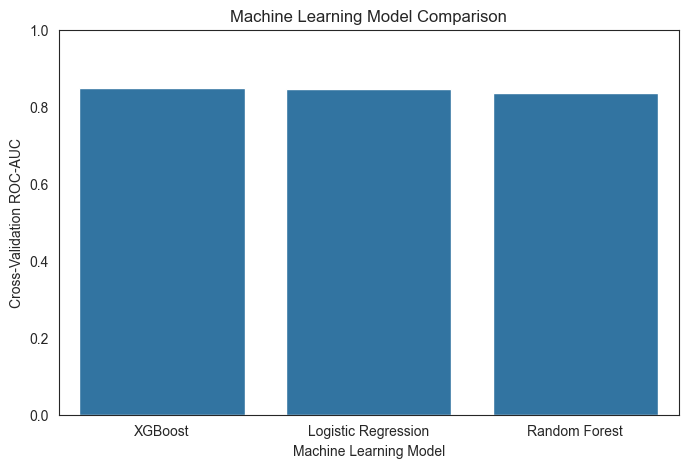

In [13]:
plt.figure(figsize=(8,5))
sns.barplot(data=comparison, x="Model", y="roc_auc_mean")
plt.title("Machine Learning Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Cross-Validation ROC-AUC")
plt.ylim(0, 1)
plt.grid(False)
plt.show()

The cross-validation results show that XGBoost achieved the highest ROC-AUC score of 0.849, followed by Logistic Regression at 0.846 and Random Forest at 0.836. Although XGBoost performed best in terms of ROC-AUC, the performance difference compared to Logistic Regression was relatively small. Therefore, performance on the test set and the model's ability to identify customers at risk of churn should also be considered when selecting the final model.

In [14]:
best_model_name = comparison.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]
best_pipeline.fit(X_train, y_train)
print("Best Model:", best_model_name)

Best Model: XGBoost


In [15]:
# Cross-validation probabilities from training data
cv_proba = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Compare different thresholds
threshold_results = []

for threshold in np.arange(0.20, 0.61, 0.05):
    y_pred_cv = (cv_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, y_pred_cv, zero_division=0
        ),
        "Recall": recall_score(
            y_train, y_pred_cv, zero_division=0
        ),
        "F1-Score": f1_score(
            y_train, y_pred_cv, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

# Select threshold based on highest F1-score
best_threshold = threshold_df.loc[
    threshold_df["F1-Score"].idxmax(),
    "Threshold"
]

print("Best Threshold:", best_threshold)

,Threshold,Precision,Recall,F1-Score
0,0.20,0.478,0.862,0.615
1,0.25,0.510,0.813,0.627
2,0.30,0.537,0.765,0.631
3,0.35,0.575,0.706,0.634
4,0.40,0.609,0.654,0.631
5,0.45,0.642,0.593,0.617
6,0.50,0.671,0.530,0.593
7,0.55,0.693,0.464,0.556
8,0.60,0.716,0.387,0.502


Best Threshold: 0.35


In [16]:
# y_pred = best_pipeline.predict(X_test)
# y_proba = best_pipeline.predict_proba(X_test)[:, 1]


y_proba = best_pipeline.predict_proba(X_test)[:, 1]

# Apply optimized threshold
y_pred = (y_proba >= best_threshold).astype(int)

In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("Average Precision:", average_precision_score(y_test, y_proba))

Accuracy: 0.7750177430801988
Precision: 0.5590062111801242
Recall: 0.7219251336898396
F1-Score: 0.6301050175029171
ROC-AUC: 0.846269601384691
Average Precision: 0.6640890921792202


In [18]:
print(classification_report(
    y_test, 
    y_pred, 
    target_names=["Non-Churn", "Churn"], 
    zero_division=0)
)

              precision    recall  f1-score   support

   Non-Churn       0.89      0.79      0.84      1035
       Churn       0.56      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.78      0.78      1409



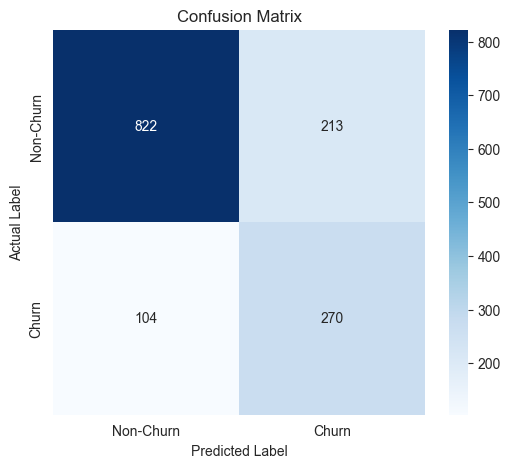

In [19]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Churn", "Churn"],
    yticklabels=["Non-Churn", "Churn"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

The confusion matrix shows that the XGBoost model correctly identified **822 non-churned customers** and **270 churned customers**. However, **213 non-churned customers** were incorrectly predicted as churned, while **104 churned customers** were not detected by the model. With a classification threshold of 0.35, the model achieved a more balanced trade-off between precision and recall, reducing false positives while maintaining the ability to identify most customers at risk of churn.

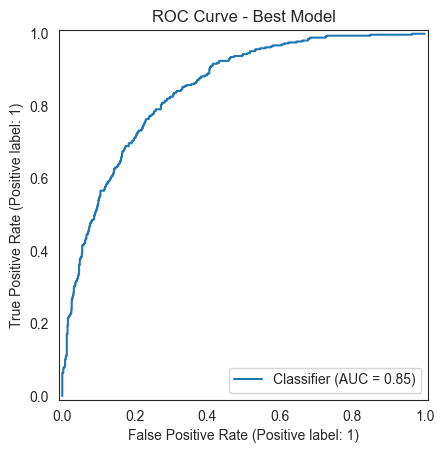

In [20]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve - Best Model")
plt.grid(False)
plt.show()

The ROC curve shows that the XGBoost model achieved an ROC-AUC score of approximately 0.85, indicating good discrimination between churned and non-churned customers. This suggests that the model can effectively distinguish customers at risk of churn across different classification thresholds.

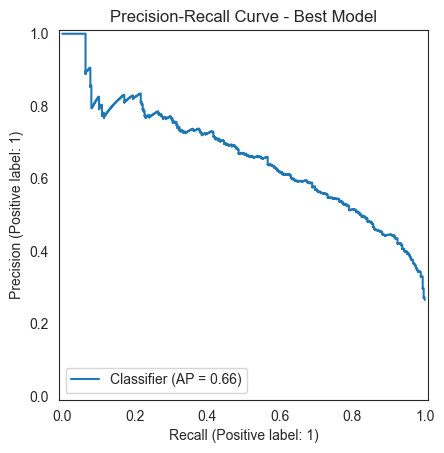

In [21]:
PrecisionRecallDisplay.from_predictions(y_test, y_proba)
plt.title("Precision-Recall Curve - Best Model")
plt.grid(False)
plt.show()

The Precision-Recall curve shows that the XGBoost model achieved an Average Precision (AP) score of 0.66, indicating a reasonable ability to identify customers at risk of churn. The curve illustrates a trade-off between precision and recall, where identifying more churned customers generally results in more false positives.

Customers were grouped into three risk levels based on their predicted churn probability: **Low (≤30%)**, **Medium (>30% to 70%)**, and **High (>70%)**. These risk categories were defined separately from the classification threshold of 0.35 and used as an initial segmentation to support customer retention strategies.

In [22]:
predictions = df.loc[X_test.index].copy()

predictions["customerID"] = id_test.to_numpy()
predictions["ChurnProbability"] = y_proba
predictions["PredictedChurn"] = y_pred

predictions["RiskLevel"] = pd.cut(
    predictions["ChurnProbability"],
    bins=[-0.001, 0.30, 0.70, 1.0],
    labels=["Low", "Medium", "High"]
)

predictions = predictions.sort_values(
    "ChurnProbability",
    ascending=False
)

display(
    predictions[
        [
            "customerID",
            "Churn",
            "ChurnProbability",
            "PredictedChurn",
            "RiskLevel"
        ]
    ].head(10)
)

,customerID,Churn,ChurnProbability,PredictedChurn,RiskLevel
3380,5178-LMXOP,1,0.923704,1,High
4585,1069-XAIEM,1,0.913117,1,High
6866,0295-PPHDO,1,0.910585,1,High
6623,9248-OJYKK,1,0.909627,1,High
2631,6861-XWTWQ,1,0.907186,1,High
2464,2609-IAICY,1,0.898700,1,High
2797,6023-YEBUP,1,0.885993,1,High
2900,0679-IDSTG,1,0.878737,1,High
1731,8375-DKEBR,1,0.878377,1,High
6748,6230-BSUXY,1,0.877465,1,High


In [23]:
risk_summary = (
    predictions["RiskLevel"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename_axis("Risk Level")
    .reset_index(name="Customers")
)

risk_summary["Percentage (%)"] = (
    risk_summary["Customers"] / risk_summary["Customers"].sum() * 100
).round(2)

display(risk_summary)


,Risk Level,Customers,Percentage (%)
0,Low,867,61.53
1,Medium,422,29.95
2,High,120,8.52


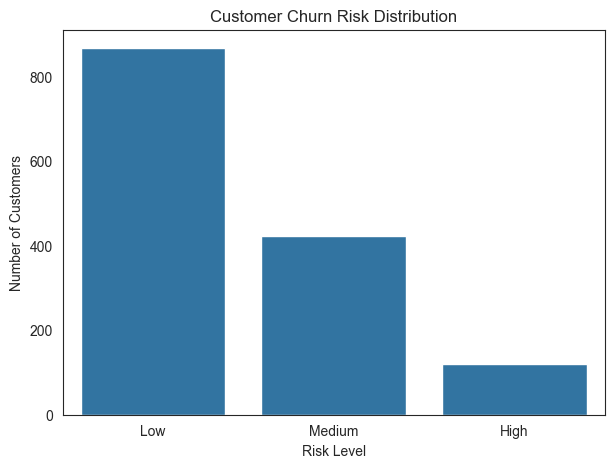

In [24]:
plt.figure(figsize=(7,5))
sns.countplot(
    data=predictions,
    x="RiskLevel",
    order=["Low", "Medium", "High"]
)
plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.grid(False)
plt.show()

Based on the predictions for 1,409 customers in the test set, **867 customers (61.53%)** were classified as Low Risk, **422 customers (29.95%)** as Medium Risk, and **120 customers (8.52%)** as High Risk. These results indicate that most customers have a relatively low predicted probability of churn. However, High Risk customers should be prioritized for targeted retention efforts, while Medium Risk customers also require attention to reduce potential churn.

In [25]:
output_data = Path("../dataset/customer_predictions_test.csv")
predictions.to_csv(output_data, index=False)

print("Prediction dataset saved successfully!")
print("File location:", output_data)

Prediction dataset saved successfully!
File location: ..\dataset\customer_predictions_test.csv


In [26]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "churn_model.joblib"
joblib.dump({
    "model": best_pipeline,
    "threshold": best_threshold
}, MODEL_PATH)

print("Model saved successfully!")
print("Model location:", MODEL_PATH)

Model saved successfully!
Model location: ..\models\churn_model.joblib


## Modeling Conclusion

Based on the comparison of three machine learning algorithms, **XGBoost** achieved the highest cross-validation ROC-AUC score of 0.849, followed by **Logistic Regression** at 0.846 and **Random Forest** at 0.836. The performance difference between XGBoost and Logistic Regression was relatively small.

After threshold tuning using F1-score optimization, a classification threshold of **0.35** was selected to balance precision and recall. On the test set, **XGBoost** achieved an accuracy of **77.50%**, precision of **55.90%**, recall of **72.19%**, F1-score of **63.01%**, and ROC-AUC of **0.846**. The improved balance between precision and recall indicates that the model can identify more customers at risk of churn compared to the default threshold, although some misclassifications remain.

The predicted churn probabilities were then used for customer risk segmentation to support the development of targeted retention strategies in the **Business Recommendations** stage.